In [2]:
# PHASE 4 — ANOMALY DETECTION NOTEBOOK SETUP

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Locate saved Phase 3 results
sessions_path = (
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

master_index_path = (
    PROJECT_ROOT
    / "outputs"
    / "diagnostics"
    / "uav_dataset_master_index.csv"
)

assert sessions_path.is_file(), f"Missing: {sessions_path}"
assert master_index_path.is_file(), f"Missing: {master_index_path}"

# Load verified datasets
sessions = pd.read_csv(sessions_path)
master_index = pd.read_csv(master_index_path)

# Validate dataset integrity
assert len(sessions) == 158
assert sessions["LogFile"].nunique() == 50
assert len(master_index) == 102

assert not sessions.duplicated(
    ["LogFile", "Session"]
).any()

print("PHASE 4 — ANOMALY DETECTION")
print("-" * 55)
print("Project root:", PROJECT_ROOT)
print("Total recordings indexed:", len(master_index))
print("Analyzable armed sessions:", len(sessions))
print("Unique session recordings:", sessions["LogFile"].nunique())

print("\nCLASSIFICATION DISTRIBUTION")
print(sessions["SessionClassification"].value_counts())

print("\nPASS: Phase 4 environment initialized!")

PHASE 4 — ANOMALY DETECTION
-------------------------------------------------------
Project root: D:\Drone-research
Total recordings indexed: 102
Analyzable armed sessions: 158
Unique session recordings: 50

CLASSIFICATION DISTRIBUTION
SessionClassification
LOW_ACTIVITY        86
REVIEW_REQUIRED     61
STRONG_CANDIDATE    11
Name: count, dtype: int64

PASS: Phase 4 environment initialized!


ANOMALY FEATURE CORRELATION MATRIX
-------------------------------------------------------


,ArmedDurationSec,TotalActivitySec,ActivityRatio,CoverageRatio
ArmedDurationSec,1.000,0.704,0.655,0.977
TotalActivitySec,0.704,1.000,0.988,0.703
ActivityRatio,0.655,0.988,1.000,0.658
CoverageRatio,0.977,0.703,0.658,1.000


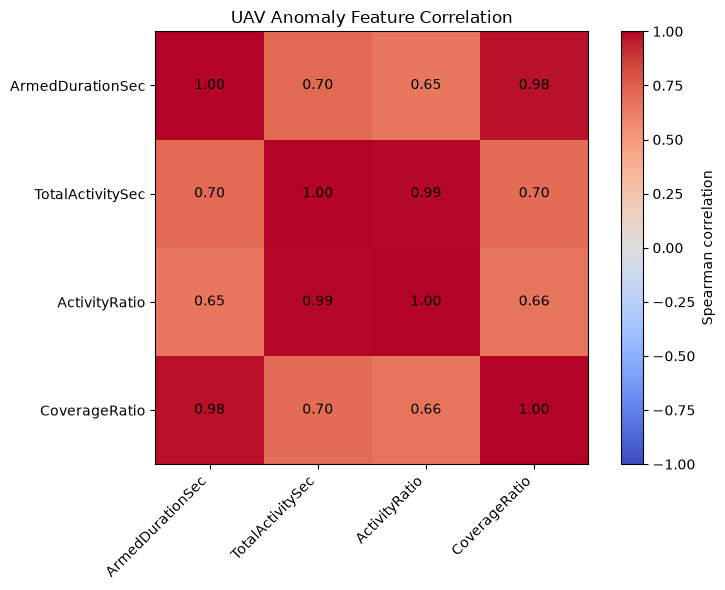


PASS: Feature correlations verified!


In [3]:
# PHASE 4 — FEATURE CORRELATION ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

features = [
    "ArmedDurationSec",
    "TotalActivitySec",
    "ActivityRatio",
    "CoverageRatio"
]

feature_data = sessions[features].apply(
    pd.to_numeric,
    errors="coerce"
)

# Verify input integrity
assert len(feature_data) == 158
assert np.isfinite(feature_data.to_numpy()).all()

# Calculate Spearman correlations
correlation_matrix = feature_data.corr(
    method="spearman"
)

print("ANOMALY FEATURE CORRELATION MATRIX")
print("-" * 55)

display(correlation_matrix.round(3))

# Visualize correlations
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(
    features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(features)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Spearman correlation")

ax.set_title("UAV Anomaly Feature Correlation")
plt.tight_layout()
plt.show()

assert correlation_matrix.notna().all().all()

print("\nPASS: Feature correlations verified!")

In [4]:
# PHASE 4 — PREPARE ANOMALY DETECTION FEATURES

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

selected_features = [
    "ArmedDurationSec",
    "ActivityRatio"
]

# Preserve session identity and original measurements
anomaly_input = sessions[
    ["LogFile", "Session"] + selected_features
].copy()

# Validate original measurements
assert len(anomaly_input) == 158
assert not anomaly_input.duplicated(
    ["LogFile", "Session"]
).any()

assert np.isfinite(
    anomaly_input[selected_features].to_numpy(
        dtype=float
    )
).all()

# Log-transform duration to reduce extreme right skew
anomaly_input["LogArmedDuration"] = np.log1p(
    anomaly_input["ArmedDurationSec"]
)

model_features = [
    "LogArmedDuration",
    "ActivityRatio"
]

# Scale features using robust statistics
scaler = RobustScaler()

X_scaled = scaler.fit_transform(
    anomaly_input[model_features]
)

assert X_scaled.shape == (158, 2)
assert np.isfinite(X_scaled).all()

print("ANOMALY MODEL INPUT PREPARATION")
print("-" * 55)

print("Sessions:", len(anomaly_input))
print("Selected model features:", model_features)
print("Scaled matrix shape:", X_scaled.shape)

print("\nFEATURE SUMMARY")
display(
    anomaly_input[model_features]
    .describe()
    .round(3)
)

print("\nFIRST FIVE SCALED ROWS")
display(
    pd.DataFrame(
        X_scaled,
        columns=model_features
    ).head().round(3)
)

print("\nPASS: Anomaly model inputs prepared!")

ANOMALY MODEL INPUT PREPARATION
-------------------------------------------------------
Sessions: 158
Selected model features: ['LogArmedDuration', 'ActivityRatio']
Scaled matrix shape: (158, 2)

FEATURE SUMMARY


,LogArmedDuration,ActivityRatio
count,158.000,158.000
mean,3.187,0.227
std,0.805,0.305
min,1.435,0.000
25%,2.389,0.000
50%,3.201,0.000
75%,3.713,0.373
max,5.609,0.927



FIRST FIVE SCALED ROWS


,LogArmedDuration,ActivityRatio
0,-0.613,0.000
1,-0.613,0.000
2,0.434,0.949
3,-0.613,0.000
4,0.420,1.846



PASS: Anomaly model inputs prepared!


In [5]:
# PHASE 4 — FIRST ISOLATION FOREST EXPERIMENT

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

# Reuse the verified scaled features
assert X_scaled.shape == (158, 2)
assert np.isfinite(X_scaled).all()

# Experimental model
isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

# Fit and detect statistically unusual sessions
predictions = isolation_model.fit_predict(X_scaled)

# Higher scores indicate more unusual observations
anomaly_scores = -isolation_model.score_samples(X_scaled)

anomaly_results = anomaly_input.copy()

anomaly_results["AnomalyScore"] = anomaly_scores
anomaly_results["AnomalyFlag"] = predictions == -1

# Preserve existing classifications for comparison only
anomaly_results["SessionClassification"] = (
    sessions["SessionClassification"].to_numpy()
)

print("ISOLATION FOREST — FIRST EXPERIMENT")
print("-" * 55)

print("Total sessions:", len(anomaly_results))
print("Flagged sessions:", anomaly_results["AnomalyFlag"].sum())
print(
    "Flagged percentage:",
    round(anomaly_results["AnomalyFlag"].mean() * 100, 2)
)

print("\nTOP 10 HIGHEST ANOMALY SCORES")

display(
    anomaly_results.sort_values(
        "AnomalyScore",
        ascending=False
    )[
        [
            "LogFile",
            "Session",
            "ArmedDurationSec",
            "ActivityRatio",
            "AnomalyScore",
            "AnomalyFlag",
            "SessionClassification"
        ]
    ].head(10).round(3)
)

assert len(anomaly_results) == 158
assert anomaly_results["AnomalyScore"].notna().all()
assert anomaly_results["AnomalyFlag"].sum() > 0
assert not anomaly_results.duplicated(
    ["LogFile", "Session"]
).any()

print("\nPASS: First Isolation Forest experiment completed!")

ISOLATION FOREST — FIRST EXPERIMENT
-------------------------------------------------------
Total sessions: 158
Flagged sessions: 8
Flagged percentage: 5.06

TOP 10 HIGHEST ANOMALY SCORES


,LogFile,Session,ArmedDurationSec,ActivityRatio,AnomalyScore,AnomalyFlag,SessionClassification
19,1980-01-11 18-54-46.bin,7,3.20,0.000,0.701,True,LOW_ACTIVITY
29,2026-07-02 18-37-42.bin,6,271.80,0.873,0.689,True,STRONG_CANDIDATE
33,2026-07-08 18-21-10.bin,1,169.95,0.927,0.683,True,STRONG_CANDIDATE
16,1980-01-11 18-54-46.bin,4,220.20,0.838,0.648,True,REVIEW_REQUIRED
25,2026-07-02 18-37-42.bin,2,135.50,0.734,0.609,True,STRONG_CANDIDATE
27,2026-07-02 18-37-42.bin,4,158.20,0.857,0.598,True,STRONG_CANDIDATE
31,2026-07-02 18-37-42.bin,8,128.50,0.806,0.596,True,STRONG_CANDIDATE
143,73 01-01-1980 05-30-00 AM.bin,8,77.60,0.093,0.595,True,REVIEW_REQUIRED
89,39 01-01-1980 05-30-00 AM.bin,4,67.00,0.000,0.591,False,LOW_ACTIVITY
142,73 01-01-1980 05-30-00 AM.bin,7,14.30,0.615,0.587,False,REVIEW_REQUIRED



PASS: First Isolation Forest experiment completed!


In [6]:
# PHASE 4 — ISOLATION FOREST VS IQR COMPARISON

import pandas as pd

# Calculate duration-based IQR thresholds
q1 = sessions["ArmedDurationSec"].quantile(0.25)
q3 = sessions["ArmedDurationSec"].quantile(0.75)

iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Start with the existing Isolation Forest results
comparison = anomaly_results.copy()

# Identify duration outliers independently
comparison["IQRDurationFlag"] = (
    (comparison["ArmedDurationSec"] < lower_bound)
    | (comparison["ArmedDurationSec"] > upper_bound)
)

# Compare detection outcomes
comparison["DetectionAgreement"] = comparison.apply(
    lambda row:
        "BOTH" if row["AnomalyFlag"] and row["IQRDurationFlag"]
        else "ISOLATION_FOREST_ONLY" if row["AnomalyFlag"]
        else "IQR_ONLY" if row["IQRDurationFlag"]
        else "NEITHER",
    axis=1
)

print("ANOMALY METHOD COMPARISON")
print("-" * 55)

print("Isolation Forest flags:",
      comparison["AnomalyFlag"].sum())

print("IQR duration flags:",
      comparison["IQRDurationFlag"].sum())

print("\nDETECTION AGREEMENT")

print(
    comparison["DetectionAgreement"].value_counts()
)

print("\nSESSIONS FLAGGED BY AT LEAST ONE METHOD")

flagged_comparison = comparison.loc[
    comparison["AnomalyFlag"]
    | comparison["IQRDurationFlag"]
].sort_values(
    "AnomalyScore",
    ascending=False
)

display(
    flagged_comparison[
        [
            "LogFile",
            "Session",
            "ArmedDurationSec",
            "ActivityRatio",
            "AnomalyFlag",
            "IQRDurationFlag",
            "DetectionAgreement",
            "SessionClassification"
        ]
    ].round(3)
)

assert comparison["AnomalyFlag"].sum() == 8
assert comparison["IQRDurationFlag"].sum() == 8
assert len(comparison) == 158

print("\nPASS: Anomaly detection methods compared!")

ANOMALY METHOD COMPARISON
-------------------------------------------------------
Isolation Forest flags: 8
IQR duration flags: 8

DETECTION AGREEMENT
DetectionAgreement
NEITHER                  148
BOTH                       6
ISOLATION_FOREST_ONLY      2
IQR_ONLY                   2
Name: count, dtype: int64

SESSIONS FLAGGED BY AT LEAST ONE METHOD


,LogFile,Session,ArmedDurationSec,ActivityRatio,AnomalyFlag,IQRDurationFlag,DetectionAgreement,SessionClassification
19,1980-01-11 18-54-46.bin,7,3.20,0.000,True,False,ISOLATION_FOREST_ONLY,LOW_ACTIVITY
29,2026-07-02 18-37-42.bin,6,271.80,0.873,True,True,BOTH,STRONG_CANDIDATE
33,2026-07-08 18-21-10.bin,1,169.95,0.927,True,True,BOTH,STRONG_CANDIDATE
16,1980-01-11 18-54-46.bin,4,220.20,0.838,True,True,BOTH,REVIEW_REQUIRED
25,2026-07-02 18-37-42.bin,2,135.50,0.734,True,True,BOTH,STRONG_CANDIDATE
27,2026-07-02 18-37-42.bin,4,158.20,0.857,True,True,BOTH,STRONG_CANDIDATE
31,2026-07-02 18-37-42.bin,8,128.50,0.806,True,True,BOTH,STRONG_CANDIDATE
143,73 01-01-1980 05-30-00 AM.bin,8,77.60,0.093,True,False,ISOLATION_FOREST_ONLY,REVIEW_REQUIRED
36,2026-07-13 18-57-45.bin,1,86.10,0.727,False,True,IQR_ONLY,REVIEW_REQUIRED
26,2026-07-02 18-37-42.bin,3,89.73,0.732,False,True,IQR_ONLY,STRONG_CANDIDATE



PASS: Anomaly detection methods compared!


In [7]:
# PHASE 4 — ISOLATION FOREST STABILITY CHECK

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

assert X_scaled.shape == (158, 2)

baseline_flags = anomaly_results["AnomalyFlag"].to_numpy()

experiment_rows = []
flag_sets = {}

for contamination in [0.03, 0.05, 0.10]:
    for seed in [7, 21, 42, 99]:

        model = IsolationForest(
            n_estimators=200,
            contamination=contamination,
            random_state=seed,
            n_jobs=-1
        )

        flags = model.fit_predict(X_scaled) == -1

        # Jaccard similarity compares sets of flagged sessions
        intersection = np.logical_and(
            baseline_flags, flags
        ).sum()

        union = np.logical_or(
            baseline_flags, flags
        ).sum()

        jaccard = intersection / union if union else 1.0

        experiment_rows.append({
            "Contamination": contamination,
            "RandomSeed": seed,
            "FlaggedSessions": int(flags.sum()),
            "OverlapWithBaseline": int(intersection),
            "JaccardSimilarity": jaccard
        })

        flag_sets[(contamination, seed)] = flags

stability_results = pd.DataFrame(experiment_rows)

print("ISOLATION FOREST STABILITY ANALYSIS")
print("-" * 60)

display(stability_results.round(3))

print("\nAVERAGE STABILITY BY CONTAMINATION")

display(
    stability_results.groupby("Contamination")
    .agg(
        MeanFlagged=("FlaggedSessions", "mean"),
        MeanJaccard=("JaccardSimilarity", "mean")
    )
    .round(3)
)

assert len(stability_results) == 12
assert stability_results["JaccardSimilarity"].between(0, 1).all()

print("\nPASS: Isolation Forest stability analysis completed!")

ISOLATION FOREST STABILITY ANALYSIS
------------------------------------------------------------


,Contamination,RandomSeed,FlaggedSessions,OverlapWithBaseline,JaccardSimilarity
0,0.03,7,5,5,0.625
1,0.03,21,5,5,0.625
2,0.03,42,5,5,0.625
3,0.03,99,5,4,0.444
4,0.05,7,8,8,1.000
5,0.05,21,8,7,0.778
6,0.05,42,8,8,1.000
7,0.05,99,8,7,0.778
8,0.10,7,16,8,0.500
9,0.10,21,16,8,0.500



AVERAGE STABILITY BY CONTAMINATION


,MeanFlagged,MeanJaccard
Contamination,,
0.03,5.0,0.580
0.05,8.0,0.889
0.10,16.0,0.500



PASS: Isolation Forest stability analysis completed!


In [8]:
# PHASE 4 — CONSENSUS ANOMALY ANALYSIS

import numpy as np
import pandas as pd

seeds = [7, 21, 42, 99]

# Results were saved in flag_sets during stability testing
flags_matrix = np.column_stack([
    flag_sets[(0.05, seed)]
    for seed in seeds
])

consensus_results = anomaly_results.copy()

consensus_results["FlagCount"] = flags_matrix.sum(axis=1)

consensus_results["FlagFrequency"] = (
    consensus_results["FlagCount"] / len(seeds)
)

consensus_results["ConsensusStatus"] = np.select(
    [
        consensus_results["FlagCount"] == 4,
        consensus_results["FlagCount"].between(1, 3)
    ],
    [
        "CONSISTENTLY_FLAGGED",
        "VARIABLE_FLAG"
    ],
    default="NOT_FLAGGED"
)

print("ANOMALY FLAG CONSENSUS")
print("-" * 55)

print(consensus_results["ConsensusStatus"].value_counts())

print("\nSESSIONS FLAGGED AT LEAST ONCE")

display(
    consensus_results.loc[
        consensus_results["FlagCount"] > 0,
        [
            "LogFile",
            "Session",
            "ArmedDurationSec",
            "ActivityRatio",
            "AnomalyScore",
            "FlagCount",
            "FlagFrequency",
            "ConsensusStatus"
        ]
    ].sort_values(
        ["FlagCount", "AnomalyScore"],
        ascending=[False, False]
    ).round(3)
)

assert len(consensus_results) == 158
assert flags_matrix.shape == (158, 4)
assert consensus_results["FlagCount"].between(0, 4).all()
assert consensus_results["FlagCount"].sum() == 32

print("\nPASS: Anomaly consensus analysis completed!")

ANOMALY FLAG CONSENSUS
-------------------------------------------------------
ConsensusStatus
NOT_FLAGGED             149
CONSISTENTLY_FLAGGED      7
VARIABLE_FLAG             2
Name: count, dtype: int64

SESSIONS FLAGGED AT LEAST ONCE


,LogFile,Session,ArmedDurationSec,ActivityRatio,AnomalyScore,FlagCount,FlagFrequency,ConsensusStatus
19,1980-01-11 18-54-46.bin,7,3.20,0.000,0.701,4,1.0,CONSISTENTLY_FLAGGED
29,2026-07-02 18-37-42.bin,6,271.80,0.873,0.689,4,1.0,CONSISTENTLY_FLAGGED
33,2026-07-08 18-21-10.bin,1,169.95,0.927,0.683,4,1.0,CONSISTENTLY_FLAGGED
16,1980-01-11 18-54-46.bin,4,220.20,0.838,0.648,4,1.0,CONSISTENTLY_FLAGGED
25,2026-07-02 18-37-42.bin,2,135.50,0.734,0.609,4,1.0,CONSISTENTLY_FLAGGED
27,2026-07-02 18-37-42.bin,4,158.20,0.857,0.598,4,1.0,CONSISTENTLY_FLAGGED
143,73 01-01-1980 05-30-00 AM.bin,8,77.60,0.093,0.595,4,1.0,CONSISTENTLY_FLAGGED
31,2026-07-02 18-37-42.bin,8,128.50,0.806,0.596,2,0.5,VARIABLE_FLAG
142,73 01-01-1980 05-30-00 AM.bin,7,14.30,0.615,0.587,2,0.5,VARIABLE_FLAG



PASS: Anomaly consensus analysis completed!


In [11]:
# FIX PROJECT IMPORT PATH

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Make the project root available to Python
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Verify the module exists
module_path = PROJECT_ROOT / "src" / "anomaly_detection.py"

print("Project root:", PROJECT_ROOT)
print("Module path:", module_path)
print("Module exists:", module_path.is_file())

assert module_path.is_file(), (
    "anomaly_detection.py is missing from the src folder!"
)

# Test the import
import src.anomaly_detection as anomaly_detection

print("\nPASS: Anomaly detection module imported successfully!")

Project root: D:\Drone-research
Module path: D:\Drone-research\src\anomaly_detection.py
Module exists: True

PASS: Anomaly detection module imported successfully!


In [12]:
import importlib
import src.anomaly_detection as anomaly_detection

importlib.reload(anomaly_detection)

anomaly_report = anomaly_detection.analyze_session_anomalies(
    sessions
)

results = anomaly_report["Sessions"]
summary = anomaly_report["Summary"]
consensus = anomaly_report["ConsensusSummary"]

print("REUSABLE ANOMALY DETECTION MODULE")
print("-" * 55)

display(summary.round(3))

print("\nCONSENSUS DISTRIBUTION")
display(consensus)

assert len(results) == 158
assert results["LogFile"].nunique() == 50

assert results["AnomalyFlag"].sum() == 8
assert results["IQRDurationFlag"].sum() == 8

assert summary.iloc[0]["BothMethods"] == 6

expected_consensus = {
    "CONSISTENTLY_FLAGGED": 7,
    "VARIABLE_FLAG": 2,
    "NOT_FLAGGED": 149
}

actual_consensus = dict(zip(
    consensus["ConsensusStatus"],
    consensus["Sessions"]
))

assert actual_consensus == expected_consensus

assert not results.duplicated(
    ["LogFile", "Session"]
).any()

print("\nPASS: Reusable anomaly detection module verified!")

REUSABLE ANOMALY DETECTION MODULE
-------------------------------------------------------


,Sessions,UniqueRecordings,IsolationForestFlags,IQRDurationFlags,BothMethods,IsolationForestOnly,IQROnly,IQRLowerThresholdSec,IQRUpperThresholdSec,Contamination,RandomState,Estimators
0,158,50,8,8,6,2,2,-35.207,85.084,0.05,42,200



CONSENSUS DISTRIBUTION


,ConsensusStatus,Sessions
0,CONSISTENTLY_FLAGGED,7
1,VARIABLE_FLAG,2
2,NOT_FLAGGED,149



PASS: Reusable anomaly detection module verified!


In [13]:
# PHASE 4 — EXPORT ANOMALY DETECTION REPORTS

from pathlib import Path
import pandas as pd

anomaly_dir = (
    PROJECT_ROOT / "outputs" / "analysis" / "anomalies"
)

anomaly_dir.mkdir(parents=True, exist_ok=True)

reports = {
    "session_anomalies.csv": results,
    "anomaly_summary.csv": summary,
    "anomaly_consensus_summary.csv": consensus
}

print("ANOMALY REPORT EXPORT")
print("-" * 55)

for filename, dataframe in reports.items():

    output_path = anomaly_dir / filename

    dataframe.to_csv(output_path, index=False)

    restored = pd.read_csv(output_path)

    assert restored.shape == dataframe.shape

    print(f"{filename}: {len(restored)} rows")

# Validate primary report after reloading
saved_anomalies = pd.read_csv(
    anomaly_dir / "session_anomalies.csv"
)

assert len(saved_anomalies) == 158

assert not saved_anomalies.duplicated(
    ["LogFile", "Session"]
).any()

assert saved_anomalies["AnomalyFlag"].sum() == 8
assert saved_anomalies["IQRDurationFlag"].sum() == 8

print("\nExport directory:", anomaly_dir)

print("\nPASS: Anomaly reports exported and verified!")


ANOMALY REPORT EXPORT
-------------------------------------------------------
session_anomalies.csv: 158 rows
anomaly_summary.csv: 1 rows
anomaly_consensus_summary.csv: 3 rows

Export directory: D:\Drone-research\outputs\analysis\anomalies

PASS: Anomaly reports exported and verified!


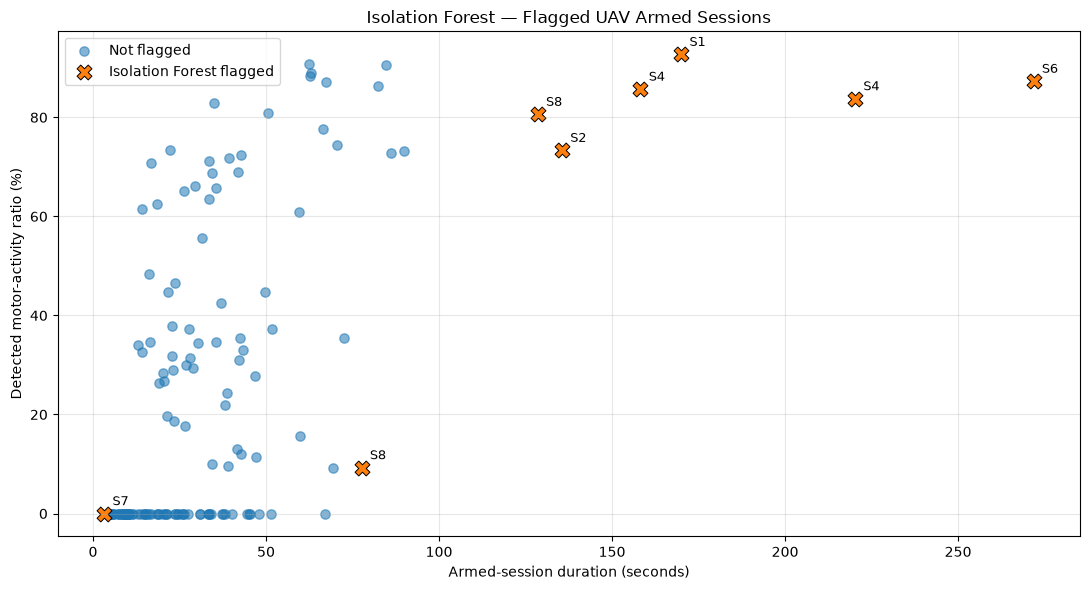

ANOMALY VISUALIZATION
--------------------------------------------------
Total sessions: 158
Flagged sessions: 8
Unflagged sessions: 150
Recordings containing flags: 4

PASS: Anomaly visualization generated!


In [14]:
# PHASE 4 — ANOMALY DETECTION VISUALIZATION

import pandas as pd
import matplotlib.pyplot as plt

anomaly_path = (
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "anomalies"
    / "session_anomalies.csv"
)

plot_data = pd.read_csv(anomaly_path)

assert len(plot_data) == 158
assert plot_data["AnomalyFlag"].sum() == 8

normal = plot_data.loc[~plot_data["AnomalyFlag"]]
flagged = plot_data.loc[plot_data["AnomalyFlag"]]

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    normal["ArmedDurationSec"],
    normal["ActivityRatio"] * 100,
    label="Not flagged",
    alpha=0.55,
    s=45
)

ax.scatter(
    flagged["ArmedDurationSec"],
    flagged["ActivityRatio"] * 100,
    label="Isolation Forest flagged",
    s=115,
    marker="X",
    edgecolors="black",
    linewidths=0.7
)

for _, row in flagged.iterrows():
    ax.annotate(
        f"S{int(row['Session'])}",
        (
            row["ArmedDurationSec"],
            row["ActivityRatio"] * 100
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Armed-session duration (seconds)")
ax.set_ylabel("Detected motor-activity ratio (%)")
ax.set_title("Isolation Forest — Flagged UAV Armed Sessions")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ANOMALY VISUALIZATION")
print("-" * 50)
print("Total sessions:", len(plot_data))
print("Flagged sessions:", len(flagged))
print("Unflagged sessions:", len(normal))
print("Recordings containing flags:", flagged["LogFile"].nunique())

print("\nPASS: Anomaly visualization generated!")

ANOMALY SCORE DISTRIBUTION
-------------------------------------------------------


count    158.0000
mean       0.4729
std        0.0730
min        0.3591
25%        0.4255
50%        0.4712
75%        0.5170
max        0.7012
Name: AnomalyScore, dtype: float64

Minimum flagged score: 0.5952
Maximum unflagged score: 0.5908


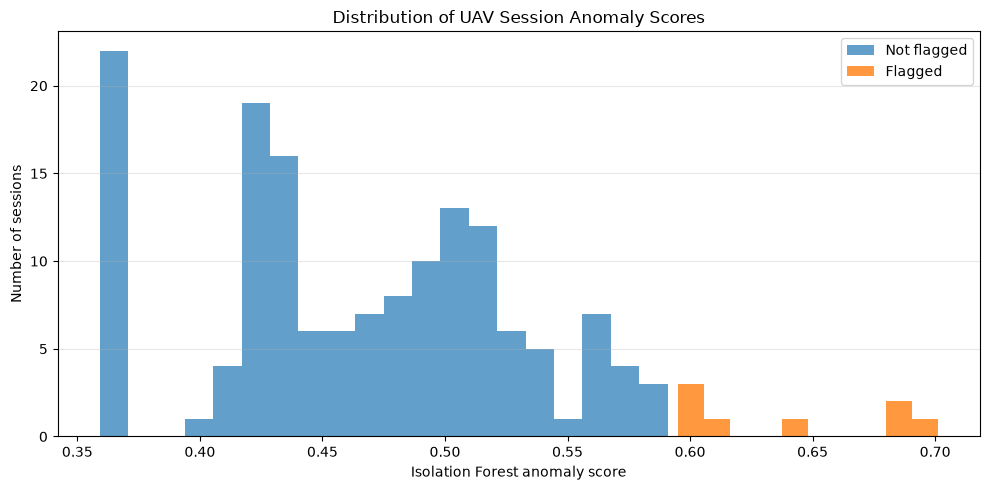


PASS: Anomaly score distribution verified!


In [15]:
# PHASE 4 — ANOMALY SCORE DISTRIBUTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

score_data = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "anomalies"
    / "session_anomalies.csv"
)

assert len(score_data) == 158
assert score_data["AnomalyFlag"].sum() == 8

scores = score_data["AnomalyScore"]

# For this fitted model, the decision cutoff is determined by
# the minimum score among flagged observations and maximum
# score among unflagged observations.
flagged_min = score_data.loc[
    score_data["AnomalyFlag"], "AnomalyScore"
].min()

unflagged_max = score_data.loc[
    ~score_data["AnomalyFlag"], "AnomalyScore"
].max()

print("ANOMALY SCORE DISTRIBUTION")
print("-" * 55)

display(scores.describe().round(4))

print("Minimum flagged score:", round(flagged_min, 4))
print("Maximum unflagged score:", round(unflagged_max, 4))

plt.figure(figsize=(10, 5))

plt.hist(
    score_data.loc[
        ~score_data["AnomalyFlag"], "AnomalyScore"
    ],
    bins=20,
    alpha=0.7,
    label="Not flagged"
)

plt.hist(
    score_data.loc[
        score_data["AnomalyFlag"], "AnomalyScore"
    ],
    bins=10,
    alpha=0.8,
    label="Flagged"
)

plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("Number of sessions")
plt.title("Distribution of UAV Session Anomaly Scores")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

assert np.isfinite(scores.to_numpy()).all()
assert flagged_min >= unflagged_max

print("\nPASS: Anomaly score distribution verified!")

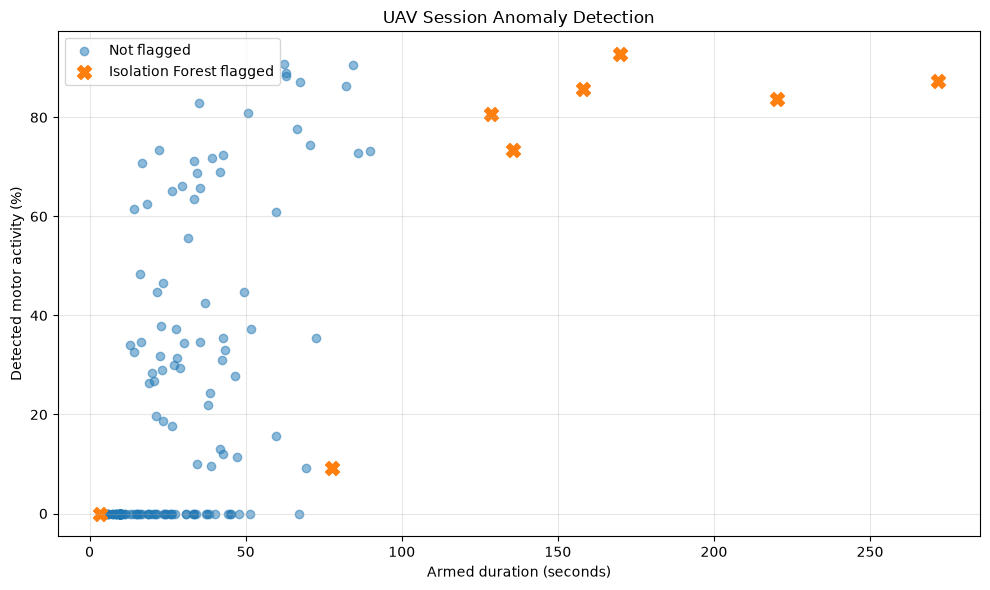

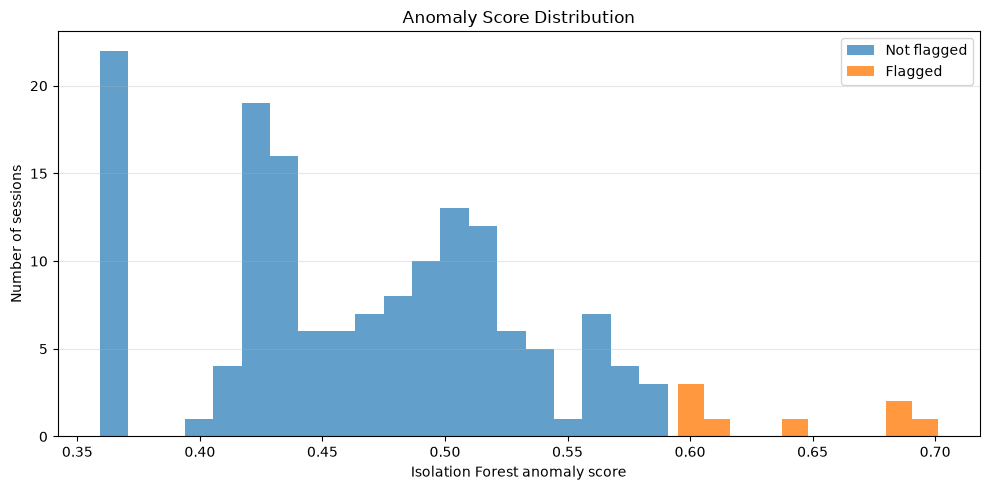


ANOMALY VISUALIZATIONS EXPORTED
-------------------------------------------------------
Scatter plot: D:\Drone-research\outputs\figures\anomalies\anomaly_scatter.png
Score distribution: D:\Drone-research\outputs\figures\anomalies\anomaly_score_distribution.png

PASS: Anomaly visualizations saved and verified!


In [16]:
# PHASE 4 — EXPORT ANOMALY VISUALIZATIONS

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

figures_dir = (
    PROJECT_ROOT / "outputs" / "figures" / "anomalies"
)
figures_dir.mkdir(parents=True, exist_ok=True)

plot_data = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "anomalies"
    / "session_anomalies.csv"
)

assert len(plot_data) == 158
assert plot_data["AnomalyFlag"].sum() == 8

normal = plot_data.loc[~plot_data["AnomalyFlag"]]
flagged = plot_data.loc[plot_data["AnomalyFlag"]]

# Figure 1 — Anomaly scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    normal["ArmedDurationSec"],
    normal["ActivityRatio"] * 100,
    alpha=0.5,
    label="Not flagged"
)

ax.scatter(
    flagged["ArmedDurationSec"],
    flagged["ActivityRatio"] * 100,
    marker="X",
    s=100,
    label="Isolation Forest flagged"
)

ax.set_xlabel("Armed duration (seconds)")
ax.set_ylabel("Detected motor activity (%)")
ax.set_title("UAV Session Anomaly Detection")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

scatter_path = figures_dir / "anomaly_scatter.png"
fig.savefig(scatter_path, dpi=200, bbox_inches="tight")
plt.show()

# Figure 2 — Score distribution
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    normal["AnomalyScore"],
    bins=20,
    alpha=0.7,
    label="Not flagged"
)

ax.hist(
    flagged["AnomalyScore"],
    bins=10,
    alpha=0.8,
    label="Flagged"
)

ax.set_xlabel("Isolation Forest anomaly score")
ax.set_ylabel("Number of sessions")
ax.set_title("Anomaly Score Distribution")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

score_path = figures_dir / "anomaly_score_distribution.png"
fig.savefig(score_path, dpi=200, bbox_inches="tight")
plt.show()

# Verify files were created
assert scatter_path.is_file()
assert score_path.is_file()

assert scatter_path.stat().st_size > 0
assert score_path.stat().st_size > 0

print("\nANOMALY VISUALIZATIONS EXPORTED")
print("-" * 55)
print("Scatter plot:", scatter_path)
print("Score distribution:", score_path)
print("\nPASS: Anomaly visualizations saved and verified!")

In [17]:
# PHASE 4 — DASHBOARD DATA READINESS

from pathlib import Path
import pandas as pd

required_files = {
    "Master index": "outputs/diagnostics/uav_dataset_master_index.csv",
    "Consolidated sessions": "outputs/analysis/consolidated_flight_sessions.csv",
    "Session manifest": "outputs/analysis/session_report_manifest.csv",
    "Statistical summary": "outputs/analysis/statistics/summary.csv",
    "Recording statistics": "outputs/analysis/statistics/recordings.csv",
    "Session anomalies": "outputs/analysis/anomalies/session_anomalies.csv",
    "Anomaly summary": "outputs/analysis/anomalies/anomaly_summary.csv",
    "Consensus summary": "outputs/analysis/anomalies/anomaly_consensus_summary.csv",
    "Anomaly scatter": "outputs/figures/anomalies/anomaly_scatter.png",
    "Anomaly scores figure": "outputs/figures/anomalies/anomaly_score_distribution.png"
}

print("DASHBOARD DATA READINESS")
print("-" * 55)

missing_files = []

for name, relative_path in required_files.items():
    path = PROJECT_ROOT / relative_path
    exists = path.is_file() and path.stat().st_size > 0

    print(f"{'OK' if exists else 'MISSING':<8} {name}")

    if not exists:
        missing_files.append(str(path))

assert not missing_files, f"Missing files: {missing_files}"

master = pd.read_csv(
    PROJECT_ROOT / required_files["Master index"]
)

session_data = pd.read_csv(
    PROJECT_ROOT / required_files["Consolidated sessions"]
)

anomalies = pd.read_csv(
    PROJECT_ROOT / required_files["Session anomalies"]
)

assert len(master) == 102
assert len(session_data) == 158
assert len(anomalies) == 158

assert set(zip(session_data["LogFile"], session_data["Session"])) == set(
    zip(anomalies["LogFile"], anomalies["Session"])
)

print("\nPASS: Dashboard data sources verified!")

DASHBOARD DATA READINESS
-------------------------------------------------------
OK       Master index
OK       Consolidated sessions
OK       Session manifest
OK       Statistical summary
OK       Recording statistics
OK       Session anomalies
OK       Anomaly summary
OK       Consensus summary
OK       Anomaly scatter
OK       Anomaly scores figure

PASS: Dashboard data sources verified!
